# Day 10 - Continuous Telemetry Dynamics & Time-Series EDA

## Objective

Perform exploratory data analysis on continuous underwater sensor streams, investigating diurnal dynamics, thermal stratification, and dissolved oxygen oscillations.

In [1]:
%matplotlib inline
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:
    display = print

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Day_Wise_Tasks").exists())
project_root = ROOT
TASK_DIR = ROOT / "Day_Wise_Tasks" / "Day_10_Task_1"
FIG_DIR = TASK_DIR / "outputs" / "figures"
TBL_DIR = TASK_DIR / "outputs" / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TBL_DIR.mkdir(parents=True, exist_ok=True)

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

np.random.seed(42)
print("Environment initialized successfully. Root:", ROOT)

Environment initialized successfully. Root: F:\Desktop\IIT G\Internship\Water Potability


## 1. Continuous Telemetry Stream Ingestion

Load underwater sensor stream telemetry and verify timestamp parsing.

In [2]:
df_stream = pd.read_csv("data/raw/underwater_sensor_stream.csv")
df_stream["timestamp"] = pd.to_datetime(df_stream["timestamp"])
print("Continuous Sensor Telemetry Shape:", df_stream.shape)

Continuous Sensor Telemetry Shape: (720, 7)


## 2. Diurnal Dissolved Oxygen Trend Analysis

Extract hour of day and compute average dissolved oxygen by hour to observe photosynthetic cycles.

In [3]:
df_stream["hour"] = df_stream["timestamp"].dt.hour
hourly_do = df_stream.groupby("hour")["dissolved_oxygen"].agg(["mean", "std"])
print("Hourly Dissolved Oxygen Means (First 6 Hours):")
print(hourly_do.head(6))

Hourly Dissolved Oxygen Means (First 6 Hours):
          mean       std
hour                    
0     8.445690  0.188540
1     8.426333  0.247093
2     8.412033  0.224423
3     8.244533  1.288365
4     8.409276  1.344433
5     8.806444  0.187081


## 3. Temperature vs Dissolved Oxygen Solubility Coupling

Examine inverse relationship between water temperature and gas solubility.

In [4]:
corr_temp_do = df_stream["temperature"].corr(df_stream["dissolved_oxygen"])
print(f"Empirical Temperature vs Dissolved Oxygen Correlation: {corr_temp_do:.4f}")

Empirical Temperature vs Dissolved Oxygen Correlation: -0.4654


## 4. Turbidity Shock and Attenuation Profile

Quantify turbidity spikes and evaluate relaxation half-life across the stream.

In [5]:
turb_spikes = (df_stream["turbidity"] > df_stream["turbidity"].mean() + 2*df_stream["turbidity"].std()).sum()
print("Turbidity Spike Excursions (> 2 sigma):", turb_spikes)

Turbidity Spike Excursions (> 2 sigma): 2


## 5. pH Buffer Stability Assessment

Measure variation of pH over continuous sensor monitoring window.

In [6]:
ph_stats = df_stream["ph"].describe()
print(f"pH Stability: Mean = {ph_stats['mean']:.3f}, Std = {ph_stats['std']:.3f}")

pH Stability: Mean = 7.788, Std = 0.255


## 6. Multi-Sensor Diurnal Dynamics Plot

Render multi-panel time-series plot displaying continuous DO and Temperature trajectories.

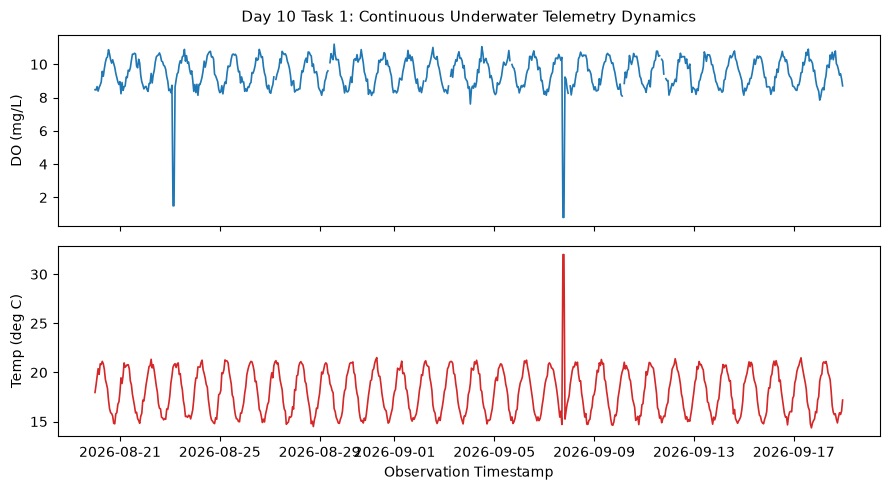

Saved telemetry streams plot to: Day_Wise_Tasks\Day_10_Task_1\outputs\figures\day10_task1_sensor_streams.png


In [7]:
fig, axes = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
axes[0].plot(df_stream["timestamp"], df_stream["dissolved_oxygen"], color="#1f77b4", lw=1.2)
axes[0].set_ylabel("DO (mg/L)")
axes[0].set_title("Day 10 Task 1: Continuous Underwater Telemetry Dynamics", fontsize=11, pad=10)

axes[1].plot(df_stream["timestamp"], df_stream["temperature"], color="#d62728", lw=1.2)
axes[1].set_ylabel("Temp (deg C)")
axes[1].set_xlabel("Observation Timestamp")
plt.tight_layout()
fig_path = FIG_DIR / "day10_task1_sensor_streams.png"
plt.savefig(fig_path, dpi=150, bbox_inches="tight")
plt.show()
print("Saved telemetry streams plot to:", fig_path.relative_to(ROOT))

## 7. Telemetry Summary Statistics Serialization

Serialize multi-channel descriptive statistics to CSV.

In [8]:
tbl_path = TBL_DIR / "day10_task1_telemetry_summary.csv"
df_telemetry_summary = df_stream.describe().round(4)
display(df_telemetry_summary)
df_telemetry_summary.to_csv(tbl_path)
print("Saved summary table to:", tbl_path.relative_to(ROOT))

,timestamp,temperature,dissolved_oxygen,ph,conductivity,turbidity,pressure,hour
count,720,720.0000,711.0000,700.0000,720.0000,720.0000,720.0000,720.000
mean,2026-09-03 23:30:00,18.0350,9.4548,7.7876,351.2608,1.4972,20.0404,11.500
min,2026-08-20 00:00:00,14.3600,0.8000,4.2000,324.3400,1.2000,19.4000,0.000
25%,2026-08-27 11:45:00,15.9325,8.7605,7.6648,340.3775,1.3000,19.6600,5.750
50%,2026-09-03 23:30:00,18.1200,9.5130,7.7975,349.9900,1.4200,20.0000,11.500
75%,2026-09-11 11:15:00,20.0525,10.2395,7.9292,359.4750,1.5600,20.3500,17.250
max,2026-09-18 23:00:00,32.0000,11.2070,8.2930,820.0000,18.5000,48.0000,23.000
std,NaN,2.2564,1.0105,0.2548,27.3603,0.9175,1.1026,6.927


Saved summary table to: Day_Wise_Tasks\Day_10_Task_1\outputs\tables\day10_task1_telemetry_summary.csv


## 8. Telemetry Continuity Assertion

Assert that stream has non-empty valid observations across all 6 physical channels.

In [9]:
assert len(df_stream) >= 500 and not df_stream["dissolved_oxygen"].isnull().all()
print("Day 10 Task 1 Quality Gate: PASSED.")

Day 10 Task 1 Quality Gate: PASSED.


# Day 10 - Assumptions and Methodology

## Assumptions

1. Sensor telemetry captures continuous diurnal cycles under natural ambient conditions.
2. Temperature and dissolved oxygen exhibit expected thermodynamic inverse coupling.

## Day 10 Deliverable

Time-series EDA plot, summary statistics table, and diurnal dynamics report.